### Making and training the model

Good things to have for ML training:

- saved checkpoints (loss history, current epoch)
- resume training
- early stopping (with or without patience counter)
- load weights mechanism

Perhaps have:
- stop training mechanism 
- early sanity checks
- memory management

In [35]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import matplotlib
import matplotlib.pyplot as plt
from datetime import datetime

import pandas as pd
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using device: {device}')

Using device: cpu


### Various functions

In [41]:
def train(model, training_dl, validation_dl, device,
          epoch_start, epochs, 
          optimizer, loss_function, performance_metric_function,
          filename,
          verbose=0,
          seed=42,
          training_history=None, validation_history=None):
    # THIS FUNCTION REFERENCES 'train' IN 'Object_localization_Kjetil_Jan' IN CELL 15 OF 32!

    assert epoch_start > 0
    assert epochs > 0

    torch.manual_seed(seed)
                        # Setting the seed for pytorch for reproducibility.

    if training_history is None:
        training_history = []
    if validation_history is None:
        validation_history = []

    model.to(device)    
                        # Moves the object to the hardware 'device'.

    n_training_batches = len(training_dl)       
                                                # len() returns the number of batches in the
                                                # dataloader dependent on batch size. There may
                                                # be a last batch with size smaller than the
                                                # given batch size.
    n_validation_batches = len(validation_dl)


    for epoch in range(epoch_start, epoch_start + epochs):
        # Training
        model.train()
                            # Sets the model in training mode and toggles 
                            # layer behaviour.

        training_loss = 0.0

        for features, labels in training_dl:
                                # Retrives a batch from the DataLoader containing
                                # the features and labels.

            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
                                # Resets the gradients (the .grad attribute)
                                # of the torch.Tensor-s.
            
            preds = model(features)     
                                # 'features' with a set batch size are vectorized
                                # and passed through the network in one operation.
                                # The ouput will be of dimensions (32, class_amount).

            loss = loss_function(preds, labels)     # Loss function calculates a mean loss of
                                                    # the multiple predictions and labels.

            loss.backward()
                                # PyTorch's AutoGrad performs backpropagation to
                                # update each trainable (requires_grad=True) tensor's 
                                # .grad attribute.

            optimizer.step()
                                # The optimizer (e.g. Adam or SGD) uses the gradients
                                # to adjust the models parameters.

            training_loss += loss.item()

        training_history.append(training_loss / n_training_batches)

        # Validation
        model.eval()
        validation_loss = 0.0
        performance = 0.0

        with torch.no_grad():
                                # Disables gradient calculation.

            for features, labels in validation_dl:
                features = features.to(device)
                labels = labels.to(device)
                preds = model(features)
                loss = loss_function(preds, labels)
                validation_loss += loss.item()

                # Performance metric
                performance += performance_metric_function(preds, labels)

        validation_history.append(validation_loss / n_validation_batches)
        performance /= n_validation_batches

        # Progress report/verbosity
        if (verbose != 0 and (epoch - epoch_start) % verbose == 0):
            print('{} | Epoch {:3d} | Train Loss: {:.3f} | Val Loss: {:.3f} | Accuracy: {:.2%}'.format(
                datetime.now().time(), epoch, training_history[-1], validation_history[-1], performance))
            # print('| Accuracy: {:3d}%'.format(
            #     performance*100
            # ))

        # Saving checkpoint/best model/final model
        if (True):
            checkpoint = {
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'model_architecture': str(model),
                'manual_seed': seed,
                'training_history': training_history,
                'validation_history': validation_history

                # To ensure dataloaders shuffle state, might need to
                # save Pythons random-module state and NumPy's.
            }
            torch.save(checkpoint, r'./model_training/' + filename + '.pth')

    return training_history, validation_history

def tensor_match(preds_logits, labels):
    '''Calculates the match between the 'preds' and 'labels'.'''
    preds = torch.argmax(preds_logits, dim=1)
    return (preds == labels).float().mean().item()

def object_localization_loss_function():
    pass

def load_weights():
    pass

def plot_loss(training_loss, validation_loss):
    fig, ax = plt.subplots(figsize=(12, 6))
    assert len(training_loss) == len(validation_loss)
    epochs = len(training_loss)
    ax.plot(range(1, epochs+1), training_loss, label='training loss')
    ax.plot(range(1, epochs+1), validation_loss, label='validation loss')
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.legend()

    
    

### Simple CNN MNIST model

In [ ]:
class MNISTmodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=(3, 3), padding=1)
        self.flat = nn.Flatten()
        self.dense1 = nn.Linear(in_features=28*28, out_features=10)
        # self.sm = nn.Softmax(dim=1)

    def forward(self, x):
        out = self.conv1(x)
        out = self.flat(out)
        out = self.dense1(out)
        # out = self.sm(out)
        return out

# Test if output dims are correct
test_model = MNISTmodel()
test_input = torch.randn(1, 1, 28, 28)
test_output = test_model(test_input)
print(f'Test-output dimensions: {test_output.shape}')
del test_model, test_input, test_output

Test-output dimensions: torch.Size([1, 10])


In [5]:
transform = transforms.Compose([ transforms.ToTensor() ])
                    # TODO How it work?

full_training_data = datasets.MNIST(
    root=r'C:\Users\klill\Documents\PyTorch_data', 
    train=True, 
                        # Downloads the 60000 images used for training.
                        # If False, it will download the 10000 seperate
                        # ones used for testing.
    download=True, 
    transform=transform
)

training_size = 50000
validation_size = 10000

training_dataset, validation_dataset = random_split(full_training_data, [training_size, validation_size])

BATCH_SIZE = 64
training_dl = DataLoader(training_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
validation_dl = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

In [98]:
model = MNISTmodel()
optimizer = torch.optim.SGD(model.parameters(), lr=0.003)

training_history, validation_history = train(
    model, training_dl, validation_dl, device,
    1, 50,
    optimizer, F.cross_entropy, tensor_match,
    'checkpoint',
    verbose=1
    )

11:32:54.884428 | Epoch   1 | Train Loss: 1.107 | Val Loss: 0.471 | Accuracy: 87.22%
11:33:04.765509 | Epoch   2 | Train Loss: 0.413 | Val Loss: 0.376 | Accuracy: 89.15%
11:33:13.895990 | Epoch   3 | Train Loss: 0.360 | Val Loss: 0.348 | Accuracy: 90.14%
11:33:23.141895 | Epoch   4 | Train Loss: 0.339 | Val Loss: 0.333 | Accuracy: 90.52%
11:33:32.107377 | Epoch   5 | Train Loss: 0.327 | Val Loss: 0.324 | Accuracy: 90.66%
11:33:40.377475 | Epoch   6 | Train Loss: 0.318 | Val Loss: 0.318 | Accuracy: 90.89%
11:33:48.993530 | Epoch   7 | Train Loss: 0.312 | Val Loss: 0.311 | Accuracy: 91.03%
11:33:57.186422 | Epoch   8 | Train Loss: 0.307 | Val Loss: 0.309 | Accuracy: 91.27%
11:34:05.475839 | Epoch   9 | Train Loss: 0.303 | Val Loss: 0.303 | Accuracy: 91.37%
11:34:13.696626 | Epoch  10 | Train Loss: 0.300 | Val Loss: 0.302 | Accuracy: 91.23%
11:34:22.076727 | Epoch  11 | Train Loss: 0.297 | Val Loss: 0.297 | Accuracy: 91.52%
11:34:30.429060 | Epoch  12 | Train Loss: 0.294 | Val Loss: 0.297

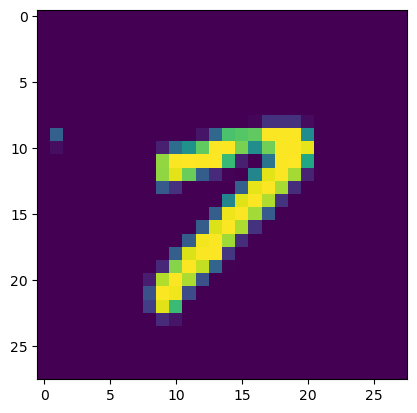

7


NameError: name 'model' is not defined

In [12]:
idx = 29
random_tensor = full_training_data[idx][0]
random_img = full_training_data[idx][0].permute(1, 2, 0).numpy()
random_label = full_training_data[idx][1]

plt.imshow(random_img)
plt.show()
print(random_label)
torch.argmax(F.softmax(model(random_tensor), dim=1)).item()

### Large and small features - CNN model

In [17]:
class LSfeaturesCNNmodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.convL = nn.Conv2d(in_channels=1, out_channels=3, kernel_size=(9, 9), padding=4)
        self.convS = nn.Conv2d(in_channels=1, out_channels=3, kernel_size=(5, 5), padding=2)
        self.flat = nn.Flatten()
        self.dense = nn.Linear(in_features=6*28*28, out_features=10)
        # self.sm = nn.Softmax(dim=1)

    def forward(self, x):
        large_features = self.convL(x)
        small_features = self.convS(x)
        concatenated_features = torch.cat((large_features, small_features), dim=1)
        flattened_features = self.flat(concatenated_features)
        logits = self.dense(flattened_features)
        # out = self.sm(out)
        return logits  

# Test if output dims are correct
test_model = MNISTmodel()
test_input = torch.randn(1, 1, 28, 28)
test_output = test_model(test_input)
print(f'Test-output dimensions: {test_output.shape}')
del test_model, test_input, test_output

Test-output dimensions: torch.Size([1, 10])


In [18]:
model = LSfeaturesCNNmodel()
optimizer = torch.optim.SGD(model.parameters(), lr=0.003)

training_history, validation_history = train(
    model, training_dl, validation_dl, device,
    1, 50,
    optimizer, F.cross_entropy, tensor_match,
    'LSfeaturesCNNmodel_checkpoint',
    verbose=1
    )

21:48:16.433696 | Epoch   1 | Train Loss: 0.805 | Val Loss: 0.431 | Accuracy: 88.17%
21:48:28.700348 | Epoch   2 | Train Loss: 0.380 | Val Loss: 0.373 | Accuracy: 89.47%
21:48:42.675699 | Epoch   3 | Train Loss: 0.343 | Val Loss: 0.352 | Accuracy: 90.04%
21:48:56.289912 | Epoch   4 | Train Loss: 0.327 | Val Loss: 0.343 | Accuracy: 90.10%
21:49:09.559728 | Epoch   5 | Train Loss: 0.317 | Val Loss: 0.333 | Accuracy: 90.53%
21:49:22.725217 | Epoch   6 | Train Loss: 0.309 | Val Loss: 0.331 | Accuracy: 90.72%
21:49:36.153645 | Epoch   7 | Train Loss: 0.304 | Val Loss: 0.326 | Accuracy: 90.56%
21:49:48.968483 | Epoch   8 | Train Loss: 0.300 | Val Loss: 0.321 | Accuracy: 91.01%
21:50:01.764855 | Epoch   9 | Train Loss: 0.296 | Val Loss: 0.320 | Accuracy: 91.00%
21:50:14.716142 | Epoch  10 | Train Loss: 0.293 | Val Loss: 0.319 | Accuracy: 91.14%
21:50:27.356155 | Epoch  11 | Train Loss: 0.290 | Val Loss: 0.318 | Accuracy: 91.25%
21:50:40.779107 | Epoch  12 | Train Loss: 0.288 | Val Loss: 0.319

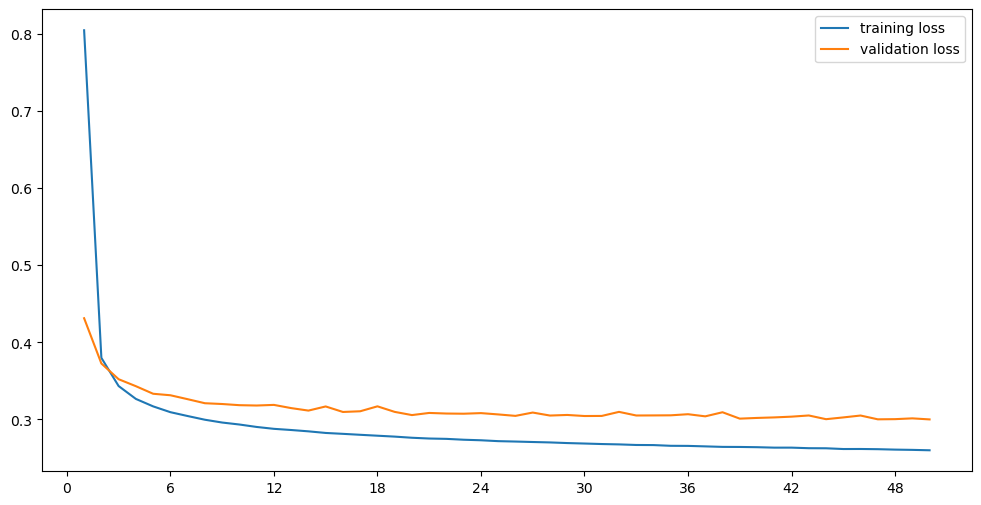

In [42]:
plot_loss(training_history, validation_history)

### Deeper CNN

In [44]:
class DeepCNNmodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28x28 -> 14x14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [45]:
model = DeepCNNmodel()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)

training_history, validation_history = train(
    model, training_dl, validation_dl, device,
    1, 50,
    optimizer, F.cross_entropy, tensor_match,
    'DeepCNNmodel_checkpoint',
    verbose=1
    )

22:28:02.189434 | Epoch   1 | Train Loss: 1.068 | Val Loss: 0.483 | Accuracy: 90.29%
22:28:30.599323 | Epoch   2 | Train Loss: 0.421 | Val Loss: 0.284 | Accuracy: 93.27%
22:28:59.027709 | Epoch   3 | Train Loss: 0.293 | Val Loss: 0.216 | Accuracy: 94.85%
22:29:27.412228 | Epoch   4 | Train Loss: 0.235 | Val Loss: 0.180 | Accuracy: 95.60%
22:29:56.367816 | Epoch   5 | Train Loss: 0.200 | Val Loss: 0.157 | Accuracy: 96.04%
22:30:24.623995 | Epoch   6 | Train Loss: 0.175 | Val Loss: 0.140 | Accuracy: 96.35%
22:30:52.870773 | Epoch   7 | Train Loss: 0.159 | Val Loss: 0.127 | Accuracy: 96.58%
22:31:21.534335 | Epoch   8 | Train Loss: 0.146 | Val Loss: 0.118 | Accuracy: 96.93%
22:31:49.798114 | Epoch   9 | Train Loss: 0.135 | Val Loss: 0.111 | Accuracy: 97.00%
22:32:18.135967 | Epoch  10 | Train Loss: 0.127 | Val Loss: 0.105 | Accuracy: 97.19%
22:32:46.313311 | Epoch  11 | Train Loss: 0.119 | Val Loss: 0.100 | Accuracy: 97.23%
22:33:14.648738 | Epoch  12 | Train Loss: 0.112 | Val Loss: 0.095

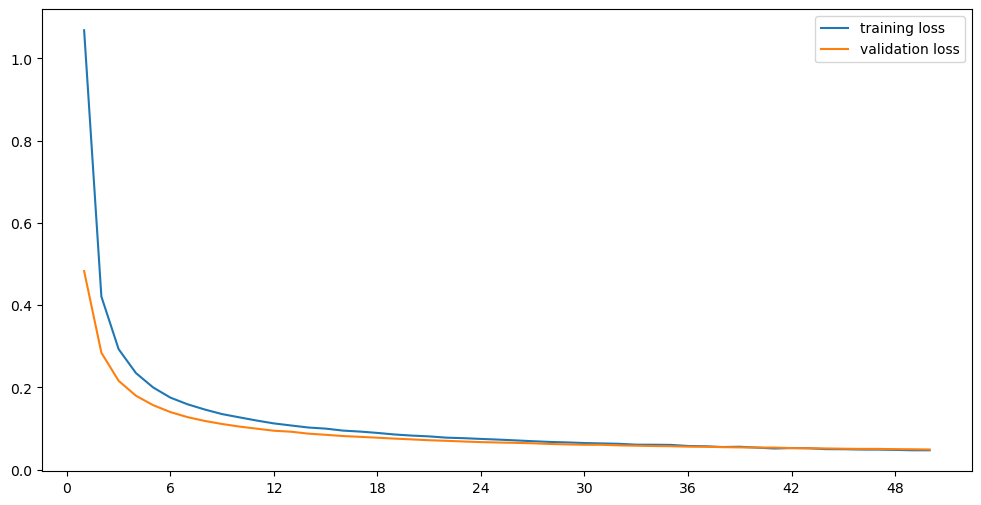

In [46]:
plot_loss(training_history, validation_history)

### Object localization for CIFAR100

In [ ]:
class ObjectLocalizationModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Assuming image dimensions 3 * 32 * 32
        conv1 = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=(3, 3), padding=1)
        flatten = nn.Flatten()
        fc1 = nn.Linear(3*32*32, )
    def forward(self, x):
        

### Alphabet

In [4]:
df = pd.read_csv(r'C:\Users\klill\Documents\PyTorch_data\az-handwritten-alphabets-in-csv-format\A_Z Handwritten Data.csv',  header=None)

In [ ]:
df[0].unique()

# The first column is the target column.
# 0 represents a, 1 represents b, 3 -> c, etc.

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25], dtype=int64)